# Small vs Large LLMs: Quality, Latency and Cost Trade-offs
## A cost-aware routing study on intent classification (MASSIVE, English)

**Dataset:** MASSIVE, English-US portion: https://huggingface.co/datasets/AmazonScience/massive

**Contents:** Introduction and problem statement · State of the art · Data and preparation · Methodology and implementation · Results · Error analysis · Interpretation and critical analysis · Limits and perspectives · Conclusion · Use of generative-AI tools · References



## Introduction and problem statement

**The question in plain words.** A company must classify user requests, for example "wake me up at seven" should become the intent `alarm_set`. A small language model is cheap and fast but errs more; a large one is accurate but costs more. Can easy requests go to the small model, with only the hard ones escalated to the large one, keeping most of the quality at a fraction of the cost? I built and tested exactly that, against fair baselines, and measured where it helps and where it doesn't.

**Why it matters.** Language-model APIs bill per token, so a service that classifies millions of short requests pays for every call. Models of different sizes have different prices (in this study the large model costs twice as much per token as the small one), and sending every request to the biggest model is the safe but expensive default. Sending only the requests that need it is the idea behind model cascades and routers (Chen et al., 2024; Ding et al., 2024; Ong et al., 2025).

**The task.** Intent classification on MASSIVE (English): given one short request, choose one of 60 intents. It is a closed-set task with one gold label per request, so accuracy is exact and "hallucination" has a precise meaning (an answer outside the 60 intents).

**Problem statement (problématique).** Take a small and a large model of the same family and a cheap non-LLM classifier as a second opinion. Then:
1. **Quality versus cost.** How much of the large model's accuracy can a router keep, and at what share of its cost?
2. **Is the routing informative?** Does the router beat *random* escalation that sends the same number of requests to the large model? If it does not, it merely picks a point on the straight line between the two models.
3. **Where does it help and where does it fail?** Which errors can the router see, which can it not, and what do invalid outputs, truncation, hallucination and overconfident stated confidence look like?

Latency is measured as a secondary criterion.

**What I did.** The small model (gpt-oss-20b) and the large model (gpt-oss-120b) answered the same 150 validation and 150 test requests once, each giving a label and a stated confidence, and every answer was cached. A TF-IDF + logistic regression classifier (S0) is the non-LLM baseline and the second opinion. The router C is computed offline from the cache: it escalates a request to the large model when the small model's output is unusable or disagrees with S0. Its selection rule was written before the sweep ran, tuned on validation only, frozen, and scored once on test. Random escalation (D), at the same number of escalated requests, is the control that guards against fooling myself. Uncertainty is quantified with paired bootstrap confidence intervals.

**What is and is not new.** Routing and cascades between language models are established ideas (next section); I do not claim novelty. What this notebook contributes is a small, fully reproducible and honestly evaluated study of one such router on a classification task, with explicit controls and an error analysis that shows where it does not help.

**Reading guide.** Data → methodology (systems, models and prompt, protocol, code) → validation analysis and router tuning → test results → error analysis → interpretation → limits → conclusion. Every number in the text comes from a code cell above it; many cells end with `assert` lines that check the output against earlier results.


## State of the art

**Using LLMs without paying for the biggest one every time.** Chen et al. (2024, "FrugalGPT") start from the observation that the prices of popular LLM APIs differ by up to two orders of magnitude, and describe three families of strategies to cut cost: adapting the prompt, approximating a big model with a cheaper one, and **LLM cascades**, where cheaper models are queried first and a more expensive one only when needed. Their cascade learns which combination of models to use per query; in their experiments it matches the best single model (GPT-4) at up to 98% lower cost, or improves accuracy at the same cost.

**Routing between a small and a large model.** Ding et al. (2024, "Hybrid LLM") route each query to a small or a large model according to its predicted difficulty and a quality level that can be tuned at test time; they report up to 40% fewer calls to the large model with no drop in response quality. Ong et al. (2025, "RouteLLM") learn routers between a strong and a weak model from human preference data with data augmentation, report cost reductions of more than two times without sacrificing response quality on public benchmarks, and find that the routers keep working when the model pair is changed at test time.

**Where this study sits.** Those works *learn* the router and evaluate it on general benchmarks. Here the router is a fixed rule, chosen on validation by a pre-written criterion, on a closed-label task where correctness is exact. Its signals are the small model's output validity and its disagreement with a cheap classifier. The aim is not to beat these systems but to measure, with controls and confidence intervals, how far such a simple router goes on a task with a clear ground truth, and what it cannot see.

**Confidence from an LLM.** A router needs a signal that says "this answer is probably wrong". A natural candidate is the model's own stated (verbalized) confidence. Tian et al. (2023) find that, for RLHF-tuned models, verbalized confidences are typically better calibrated than token probabilities on their question-answering benchmarks. Xiong et al. (2024) find that LLMs tend to be overconfident when they verbalize confidence, which prompting and sampling strategies only partly mitigate. Calibration is classically visualised with reliability diagrams, which plot accuracy as a function of confidence (Guo et al., 2017). I use binned reliability tables on validation to check whether the two models' stated confidence is usable as a routing signal.


## Data and preparation

**Dataset.** MASSIVE (Amazon), English-US portion: short spoken-style requests to a virtual assistant, each labelled with one of **60 intents** (e.g. `alarm_set`, `email_query`, `qa_definition`). Intents are grouped into **18 scenarios**, the part of the name before the first underscore (`alarm`, `email`, `qa`, ...). Dataset link: https://huggingface.co/datasets/AmazonScience/massive. MASSIVE (FitzGerald et al., 2023) is derived from SLURP (Bastianelli et al., 2020), an English collection of voice-assistant requests; its other 50 languages are professional-translator localizations of it. It is not a log of real production traffic.

**Splits** (11,514 train, 2,033 validation, 2,974 test requests) and what each is used for:

| Split | Used for |
|---|---|
| train | training S0 (TF-IDF + logistic regression). Never shown to the LLMs, which are zero-shot. |
| validation | S0's regularization (C = 100, chosen on the full split), calibration analysis, and choosing the router's configuration (60-config sweep) |
| test | scoring every system once, with the frozen configuration |

**Samples.** The free API plan (per model: 200,000 tokens per day, 8,000 per minute) cannot score full splits, so I drew **150 validation and 150 test requests once** (seed 42) and saved their ids in `samples.json`, which is committed to git. Every system, including S0, is scored on exactly these rows.

**What the data looks like.**
- **Strong class imbalance.** Training examples per intent range from 4 to 810 (median 128), about 200 times between the extremes. The most frequent intent is `calendar_set`.
- **The samples miss some intents.** The test sample covers 45 of the 60 intents (validation: 46), so 15 intents never appear in it. Accuracy cannot see them, and macro-F1 is computed over the intents present in each sample (the protocol's choice). The 15 missing intents all have at most 125 training examples (median 54, against a median of 128 over all 60 intents) and together make up 7.4% of the full test split, about 0.5% each. At that size, a typical intent has roughly even odds of being absent from a 150-row draw, so the gap is consistent with chance. Rare intents that do appear have only one or two rows, so their F1 swings with a single error. I draw no conclusions about individual rare intents.
- **Requests are very short.** Median 6 words in train, in the full test split and in the test sample (mean 6.9, 6.8, 6.5; 95th percentile 13, 13, 11; longest 35, 61, 19). Nothing is truncated. The sample's tail is shorter than the full data's, as expected for a draw of 150.
- **Text is used as given.** The requests I read are lowercase with little or no punctuation. I did not clean or edit them: S0 sees word 1-2-gram TF-IDF features and the LLMs see the text as is.
- **Labels are imperfect.** Some requests carry almost no signal ("seven years", "topic", "wedding wishes"), and some intent names overlap (`email_query` vs `email_querycontact`, `iot_hue_lighton` vs `iot_hue_lightup`). The error analysis quantifies this on the hardest rows.

train / val / test: 11514 2033 2974
intents: 60 | scenarios: 18
train examples per intent: min 4 | median 128 | max 810
words per utterance, train             : median 6 | mean 6.9 | p95 13 | max 35
words per utterance, test (full)       : median 6 | mean 6.8 | p95 13 | max 61
words per utterance, test (150 sample) : median 6 | mean 6.5 | p95 11 | max 19
classes absent from the 150 test rows: 15


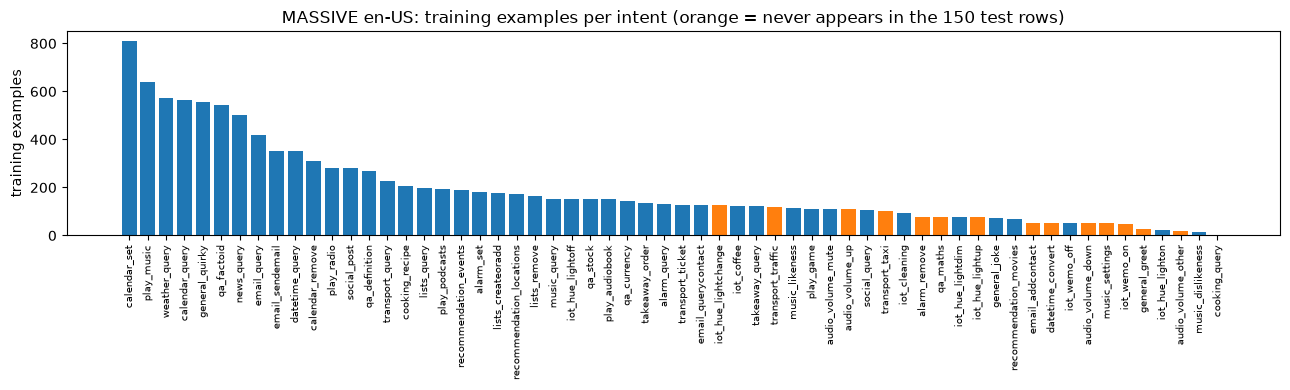

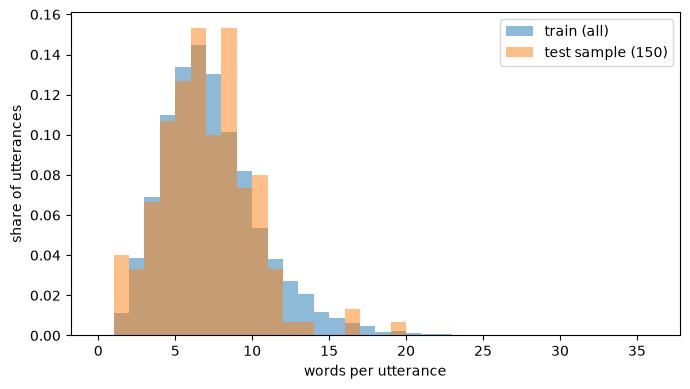

In [1]:
import json
import matplotlib.pyplot as plt
from data import load_massive

dfs, label_names = load_massive()
for s in dfs:
    dfs[s]["id"] = dfs[s]["id"].astype(int)              # ids arrive as strings
ids  = {k: {int(i) for i in v} for k, v in json.load(open("samples.json")).items()}
samp = {s: dfs[s][dfs[s]["id"].isin(ids[s])] for s in ["validation", "test"]}

# ---- checks against what we already know ----
assert {s: len(d) for s, d in dfs.items()} == {"train": 11514, "validation": 2033, "test": 2974}
assert len(label_names) == 60
assert len(samp["validation"]) == 150 and len(samp["test"]) == 150
assert samp["validation"]["label"].nunique() == 46 and samp["test"]["label"].nunique() == 45

# ---- numbers for the data notes ----
cnt = dfs["train"]["label"].value_counts()
scn = dfs["train"]["label"].str.split("_").str[0].nunique()
assert scn == 18
print("train / val / test:", len(dfs["train"]), len(dfs["validation"]), len(dfs["test"]))
print("intents:", len(label_names), "| scenarios:", scn)
print("train examples per intent: min", cnt.min(), "| median", int(cnt.median()), "| max", cnt.max())

words = {"train": dfs["train"].utt.str.split().str.len(),
         "test (full)": dfs["test"].utt.str.split().str.len(),
         "test (150 sample)": samp["test"].utt.str.split().str.len()}
for name, w in words.items():
    print(f"words per utterance, {name:18s}: median {w.median():.0f} | mean {w.mean():.1f} | p95 {w.quantile(.95):.0f} | max {w.max()}")

absent = sorted(set(label_names) - set(samp["test"]["label"]))
assert len(absent) == 15
print("classes absent from the 150 test rows:", len(absent))

# ---- chart 1: class counts in train; orange = absent from the test sample ----
fig, ax = plt.subplots(figsize=(13, 4))
colors = ["tab:orange" if c in absent else "tab:blue" for c in cnt.index]
ax.bar(range(len(cnt)), cnt.values, color=colors)
ax.set_xticks(range(len(cnt)))
ax.set_xticklabels(cnt.index, rotation=90, fontsize=7)
ax.set_ylabel("training examples")
ax.set_title("MASSIVE en-US: training examples per intent (orange = never appears in the 150 test rows)")
plt.tight_layout()
plt.show()

# ---- chart 2: utterance length ----
fig, ax = plt.subplots(figsize=(7, 4))
bins = range(0, int(words["train"].max()) + 2)
ax.hist(words["train"], bins=bins, density=True, alpha=0.5, label="train (all)")
ax.hist(words["test (150 sample)"], bins=bins, density=True, alpha=0.5, label="test sample (150)")
ax.set_xlabel("words per utterance")
ax.set_ylabel("share of utterances")
ax.legend()
plt.tight_layout()
plt.show()

In [2]:
print("train count of the 15 absent classes: max", cnt[absent].max(), "| median", int(cnt[absent].median()))
print("share of the FULL test split in those 15 classes:", round(dfs["test"]["label"].isin(absent).mean(), 3))

train count of the 15 absent classes: max 125 | median 54
share of the FULL test split in those 15 classes: 0.074


## Methodology

### The pipeline in one picture

```
request --> small LLM --> label + stated confidence --+
   |                                                  +--> router C: escalate?
   +----> S0 (TF-IDF + LR) --> label + probability ---+        |no : keep the small model's answer
                                                               |yes: ask the large LLM, use its answer
```

### Systems compared

| System | What it is | How cost and latency are obtained |
|---|---|---|
| **S0** | TF-IDF (word 1-2-grams, sublinear term frequency) + logistic regression, C = 100 chosen on the full validation split, trained on the 11,514 labelled training requests | no API cost; latency not measured |
| **A: small** | gpt-oss-20b alone, zero-shot | cost from token counts times the published price; measured latency |
| **B: large** | gpt-oss-120b alone, zero-shot | same as A |
| **C: router** | small model on every request, then the large model on the escalated requests; the final answer is the large model's for escalated requests and the small model's otherwise | cost = small on all requests + large on escalated ones; latency = small + large (sequential) for escalated requests, obtained by adding two separately measured latencies, not by timing a running pipeline |
| **D: random escalation** | same as C but the escalated requests are chosen at random, with exactly as many as C escalates; averaged over many random draws (1,000 for the test metrics, 2,000 in the validation sweep) | same formulas as C |

A and B were run **once** on every validation and test request and cached. C and D are computed offline from that cache, so they cost no extra API calls.

### The router C

C escalates a request to the large model if **any** of these fires: (1) the small model's output is invalid (always on); (2) its stated confidence is below a threshold `t_v`; (3) S0's top probability is below a threshold `t_s`; (4) the small model's label disagrees with S0's label (switchable). A threshold of 0 switches that signal off. The rule that picks the configuration was written before the sweep ran and is shown in the section "Operating-point rule" below. The configuration it picked, frozen before any test result was computed, is `t_v = 0, t_s = 0, use_disagree = True`: **escalate when the small model's output is invalid or its label differs from S0's.**

The intuition: S0 is a second, independent opinion. When two different classifiers agree, the answer is usually right; when they disagree, at least one of them is wrong, so it is worth paying for a third opinion from the large model.

### Models and prompt

- **Models.** gpt-oss-20b (small) and gpt-oss-120b (large), two open-weight reasoning models of the same family (OpenAI, 2025). Using one family keeps training recipe and answer style constant, so the comparison is mostly about size. According to the model card the large model has about 117B total parameters (5.1B active per token) and the small about 21B (3.6B active); so "large" is about 5-6 times bigger in total size but much closer in compute per token. Both run on the Groq free plan, with `reasoning_effort = "low"` (the model card describes low as the fast setting), so **cost is estimated from the published per-million-token prices**: small USD 0.075 input / 0.30 output, large USD 0.15 input / 0.60 output. The large model therefore costs exactly twice as much per token.
- **Prompting strategy.** Zero-shot: no examples. The prompt lists the 60 label names (names only, no descriptions) and asks for one JSON object `{"intent": ..., "confidence": ...}`. The confidence is text the model writes after its label, not an internal probability. The prompt and the generation parameters were fixed before any run and never edited afterwards (the cache key hashes the model, the messages and the parameters, so any change would trigger new calls). The exact prompt and all parameters are printed by the code cell below.
- **Why zero-shot with names only.** It needs no labelled data (the "cold start" setting where LLMs are attractive), it keeps the comparison simple, and it avoids tuning a prompt on the same 150 validation rows I later use to tune the router. Richer prompts (label descriptions, retrieved examples) are left as a perspective.
- **Hallucination, defined for this task.** A syntactically valid answer naming an intent outside the 60. Separate from this are *invalid outputs* (no usable JSON), which count as wrong.

### Evaluation protocol

1. **Samples.** 150 validation and 150 test requests, drawn once (seed 42); their ids are stored in `samples.json` and tracked in git. Every system, including S0, is scored on exactly these rows.
2. **Roles of the splits.** Validation: calibration analysis, choice of routing signals, the 60-configuration sweep. Test: scored **once**, with the frozen configuration. After that, test errors are read to understand them, and nothing is re-tuned.
3. **Pre-registered choice.** The selection rule (the configurations with at least 20% estimated cost saving versus B on validation; among them, highest validation accuracy, ties to lower cost) was written before the sweep. The git history records the order: the commit "Freeze router config (chosen on validation, before test)" comes before the commit with the test results.
4. **Metrics.** Accuracy; macro-F1 (computed over the classes present in the sample); invalid-output rate; median and 95th-percentile latency; cost per 1,000 requests, from token counts times price; escalation rate. Micro-F1 is not reported because for single-label classification it equals accuracy.
5. **Uncertainty.** Paired bootstrap on the 150 test rows (5,000 resamples, the same resampled rows for every system, router decisions held fixed): 95% intervals for accuracies, for differences between systems, for the cost saving and for the share of B's accuracy that C keeps. No intervals for macro-F1 or latency (too noisy at n = 150), so those are descriptive.
6. **Controls and sanity checks.** D (random escalation at equal count) tests whether the router's choices carry information. Asserts check that "escalate nobody" reproduces A's predictions and cost, that "escalate everybody" reproduces B's predictions, and that D's expected accuracy lies on the straight line from A to B.

### Notions used in this notebook (also explained in the oral presentation)

- **Token:** the unit APIs count and bill, roughly a word or a word fragment.
- **Reasoning model / reasoning effort:** the model writes hidden "thinking" tokens before its visible answer. They are billed as completion tokens and count toward the output cap; the effort setting (low, medium, high) controls how much it thinks.
- **Verbalized confidence:** a number the model writes as text next to its label.
- **Calibration, reliability table:** group answers by stated confidence and compare with the real accuracy in each group. A well-calibrated model that says 0.9 is right about 90% of the time; an overconfident one is right less often.
- **AUROC:** the probability that a randomly chosen correct answer gets a higher score than a randomly chosen wrong one. 0.5 is chance, 1.0 is a perfect ranking.
- **Macro-F1:** F1 computed per class and then averaged, so rare classes count as much as frequent ones.
- **Bootstrap confidence interval:** resample the 150 rows with replacement, recompute the metric, repeat 5,000 times; the middle 95% of the results is the interval. "Paired" means all systems are evaluated on the same resampled rows, so differences between systems are measured fairly.
- **Winner's curse:** picking the best of many options on a small sample overstates how good the winner is.
- **Cascade / router:** ask a cheap model first and escalate to an expensive one only when a rule says so.


### Implementation: the project's scripts

The plumbing lives in small scripts, one per job: `config.py` (constants, model ids, prices), `data.py` (loading MASSIVE and the frozen samples), `s0.py` (the baseline, writes `cache/s0_preds.csv`), `prompt.py` (the prompt), `llm.py` (the Groq wrapper with an on-disk cache, request pacing and retry on rate limits), `run_llm.py` (runs A and B on validation and test, writes `cache/llm_results.csv`). The cell below only **prints** their source so this notebook is self-contained; it makes no API call. The router, system D, the metrics and the analysis are written in the notebook cells themselves.


In [3]:
from pathlib import Path

# Prints the project's own scripts. This cell only READS text files: no API call.
_FILES = ["config.py", "data.py", "s0.py", "prompt.py", "llm.py", "run_llm.py"]

for _name in _FILES:
    _p = Path(_name)
    print("=" * 78)
    print(f"# {_name}")
    print("=" * 78)
    if not _p.exists():
        print("[file not found in the notebook's folder]\n")
        continue
    for _line in _p.read_text(encoding="utf-8").splitlines():
        print("<line hidden: looks like an API key>" if "gsk_" in _line else _line)
    print()


# config.py
SEED = 42
N_VAL = 150
N_TEST = 150


MODELS = {
    "small": {"id": "openai/gpt-oss-20b", "price_in_per_M": 0.075, "price_out_per_M": 0.30,
              "rpm": 30, "rpd": 1000, "tpm": 8000, "tpd": 200_000},
    "large": {"id": "openai/gpt-oss-120b", "price_in_per_M": 0.15, "price_out_per_M": 0.60,
              "rpm": 30, "rpd": 1000, "tpm": 8000, "tpd": 200_000},
}

LLM_PARAMS = dict(temperature=0, reasoning_effort="low", max_completion_tokens=400)

# data.py
from huggingface_hub import hf_hub_download
from datasets import Dataset


import json, os
from config import SEED, N_VAL, N_TEST

SAMPLES_PATH = "samples.json"

def get_samples(dfs, path=SAMPLES_PATH):
    """Return {'validation': df, 'test': df}. Draws once, then always reloads the same ids."""
    if os.path.exists(path):
        with open(path) as f:
            ids = json.load(f)
    else:
        ids = {
            "validation": dfs["validation"].sample(N_VAL, random_state=SEED)["id"].tolist(),
            "te

### Implementation: loading the cached answers, per-request cost, and the metrics function

The next three cells join the cached small-model and large-model answers with S0's predictions into one table (one row per request), compute each request's estimated cost from its token counts, and define the single `metrics()` function that is applied unchanged to S0, A, B, C and D.


In [4]:
import numpy as np
import pandas as pd
from pathlib import Path

CACHE = Path("cache")
KEYS = ["split", "id"]

# --- load ---
llm = pd.read_csv(CACHE / "llm_results.csv")
s0  = pd.read_csv(CACHE / "s0_preds.csv")

# --- the three gotchas ---
llm["id"]   = llm["id"].astype(int)
s0["id"]    = s0["id"].astype(int)
llm["text"] = llm["text"].fillna("")          # failed outputs have empty text
llm["pred"] = llm["pred"].fillna("INVALID")   # invalid counts as wrong

assert set(llm["model"]) == {"small", "large"}, set(llm["model"])

# --- one row per (split, id), models side by side ---
def side(model):
    d = llm[llm["model"] == model].drop(columns="model")
    return d.rename(columns={c: f"{model}_{c}" for c in d.columns if c not in KEYS})

df = side("small").merge(side("large"), on=KEYS, validate="one_to_one")
assert (df["small_gold"] == df["large_gold"]).all()
df["gold"] = df["small_gold"]
df = df.drop(columns=["small_gold", "large_gold"])
df = df.merge(s0, on=KEYS, how="inner", validate="one_to_one")

# --- sanity checks against Day 2 ---
print("rows per split:\n", df["split"].value_counts(), "\n")
print("columns with NaN:\n", df.isna().sum()[lambda s: s > 0], "\n")

for split, g in df.groupby("split"):
    print(split,
          f"| S0 {(g.s0_pred == g.gold).mean():.3f}",
          f"| small {(g.small_pred == g.gold).mean():.3f}",
          f"| large {(g.large_pred == g.gold).mean():.3f}",
          f"| invalid small/large {(g.small_pred == 'INVALID').sum()}/{(g.large_pred == 'INVALID').sum()}")

rows per split:
 split
validation    150
test          150
Name: count, dtype: int64 

columns with NaN:
 small_confidence    2
dtype: int64 

test | S0 0.800 | small 0.700 | large 0.780 | invalid small/large 1/0
validation | S0 0.787 | small 0.767 | large 0.793 | invalid small/large 1/0


In [5]:
# USD per 1M tokens: (input, output). Published Groq prices; we're on the free tier,
# so this is an ESTIMATE of what the same calls would cost on a paid plan.
PRICES = {"small": (0.075, 0.30), "large": (0.15, 0.60)}

def row_cost(prompt_tokens, completion_tokens, model):
    p_in, p_out = PRICES[model]
    return (prompt_tokens * p_in + completion_tokens * p_out) / 1_000_000

for m in PRICES:
    df[f"{m}_cost"] = row_cost(df[f"{m}_prompt_tokens"], df[f"{m}_completion_tokens"], m)

# check against Day 2 (all 300 rows per model): expect large ~0.0813, small ~0.0418
print((df[["small_cost", "large_cost"]].mean() * 1000).round(4))

small_cost    0.0418
large_cost    0.0813
dtype: float64


In [6]:
from sklearn.metrics import f1_score

def metrics(gold, pred, latency=None, cost=None):
    """One function for every system (S0, A, B, and later C, D).
    gold, pred: label per request ("INVALID" = unusable output, counts as wrong)
    latency:    seconds per request (None if not measured)
    cost:       USD per request     (None if not applicable)
    """
    gold, pred = np.asarray(gold), np.asarray(pred)
    present = sorted(set(gold))                      # classes that appear in THIS sample
    out = {
        "n": len(gold),
        "acc": (gold == pred).mean(),
        "macro_f1": f1_score(gold, pred, labels=present, average="macro", zero_division=0),
        "invalid_rate": (pred == "INVALID").mean(),
        "lat_median": np.nan, "lat_p95": np.nan, "cost_per_1k": np.nan,
    }
    if latency is not None:
        out["lat_median"] = np.median(latency)
        out["lat_p95"] = np.percentile(latency, 95)
    if cost is not None:
        out["cost_per_1k"] = np.mean(cost) * 1000
    return out

def system_table(g):
    return pd.DataFrame({
        "S0":      metrics(g.gold, g.s0_pred),
        "A small": metrics(g.gold, g.small_pred, g.small_latency_s, g.small_cost),
        "B large": metrics(g.gold, g.large_pred, g.large_latency_s, g.large_cost),
    }).T

for split in ["validation", "test"]:
    print(f"=== {split} ===")
    print(system_table(df[df["split"] == split]).round(3), "\n")

=== validation ===
             n    acc  macro_f1  invalid_rate  lat_median  lat_p95  \
S0       150.0  0.787     0.767         0.000         NaN      NaN   
A small  150.0  0.767     0.821         0.007       1.357    2.127   
B large  150.0  0.793     0.803         0.000       1.398    2.571   

         cost_per_1k  
S0               NaN  
A small        0.042  
B large        0.081   

=== test ===
             n   acc  macro_f1  invalid_rate  lat_median  lat_p95  cost_per_1k
S0       150.0  0.80     0.791         0.000         NaN      NaN          NaN
A small  150.0  0.70     0.769         0.007       1.432    2.080        0.042
B large  150.0  0.78     0.829         0.000       1.471    2.308        0.081 



### Routing signals: calibration analysis (validation only)

Before designing the router I check which signals can tell when the small model is wrong: its stated confidence, S0's probability, and whether the two models' labels agree. Everything here uses the **validation** sample only.


In [7]:
from sklearn.metrics import roc_auc_score

val = df[df["split"] == "validation"].copy()
val["small_ok"] = val.small_pred == val.gold
val["large_ok"] = val.large_pred == val.gold
val["s0_ok"]    = val.s0_pred    == val.gold

# What values does verbalized confidence actually take? (before choosing any bins)
for m in ["small", "large"]:
    print(f"--- {m} verbalized confidence, validation ---")
    print(val[f"{m}_confidence"].value_counts(dropna=False).sort_index().to_string(), "\n")

--- small verbalized confidence, validation ---


small_confidence
0.10     2
0.20     1
0.30     2
0.40     4
0.60     4
0.85     5
0.92    32
0.95     8
0.99    91
NaN      1 

--- large verbalized confidence, validation ---
large_confidence
0.30     1
0.45     2
0.78    10
0.87     1
0.88     2
0.92    19
0.96    34
0.97    59
0.99    22 



In [8]:
def reliability(conf, ok, bins):
    d = pd.DataFrame({"conf": conf, "ok": ok}).dropna()          # NaN confidence = invalid output, handled separately
    d["bin"] = pd.cut(d["conf"], bins=bins, include_lowest=True)
    t = d.groupby("bin", observed=True).agg(n=("ok", "size"),
                                            mean_conf=("conf", "mean"),
                                            accuracy=("ok", "mean"))
    return t.round(3)

def summarize(name, conf, ok, bins):
    d = pd.DataFrame({"conf": conf, "ok": ok}).dropna()
    print(f"=== {name} ===")
    print(f"rows with a confidence: {len(d)} of {len(conf)}")
    print(f"mean confidence | right: {d[d.ok].conf.mean():.3f}   wrong: {d[~d.ok].conf.mean():.3f}")
    print(f"AUROC (does confidence rank right above wrong?): {roc_auc_score(d.ok, d.conf):.3f}")
    print(reliability(conf, ok, bins).to_string(), "\n")

BINS_VERB = [0, 0.5, 0.8, 0.9, 0.95, 0.99, 1.0]   # coarse: only 150 rows
BINS_S0   = [0, 0.3, 0.5, 0.7, 0.9, 1.0]

summarize("small, verbalized", val.small_confidence, val.small_ok, BINS_VERB)
summarize("large, verbalized", val.large_confidence, val.large_ok, BINS_VERB)
summarize("S0 probability",    val.s0_conf,          val.s0_ok,    BINS_S0)

=== small, verbalized ===
rows with a confidence: 149 of 150
mean confidence | right: 0.969   wrong: 0.734
AUROC (does confidence rank right above wrong?): 0.796
                n  mean_conf  accuracy
bin                                   
(-0.001, 0.5]   9      0.289     0.000
(0.5, 0.8]      4      0.600     0.250
(0.8, 0.9]      5      0.850     0.000
(0.9, 0.95]    40      0.926     0.800
(0.95, 0.99]   91      0.990     0.901 

=== large, verbalized ===
rows with a confidence: 150 of 150
mean confidence | right: 0.954   wrong: 0.880
AUROC (does confidence rank right above wrong?): 0.808
                 n  mean_conf  accuracy
bin                                    
(-0.001, 0.5]    3      0.400     0.333
(0.5, 0.8]      10      0.780     0.600
(0.8, 0.9]       3      0.877     0.000
(0.9, 0.95]     19      0.920     0.474
(0.95, 0.99]   115      0.971     0.896 

=== S0 probability ===
rows with a confidence: 150 of 150
mean confidence | right: 0.936   wrong: 0.507
AUROC (does con

In [9]:
target = val.small_ok

signals = {
    "small verbalized conf (invalid -> 0)": val.small_confidence.fillna(0),
    "S0 probability":                       val.s0_conf,
}
for name, s in signals.items():
    print(f"AUROC for 'small is right' | {name:38s} {roc_auc_score(target, s):.3f}")

# disagreement signal: does the small model's answer match S0's?
val["agree"] = val.small_pred == val.s0_pred      # an INVALID output never matches, so it counts as disagree
print("\nsmall model accuracy, split by agreement with S0:")
print(val.groupby("agree").agg(n=("small_ok", "size"), small_acc=("small_ok", "mean")).round(3))

print("\nS0 probability, rows where small is right vs wrong:")
print(val.groupby("small_ok").s0_conf.agg(["count", "mean", "median"]).round(3))

AUROC for 'small is right' | small verbalized conf (invalid -> 0)   0.802
AUROC for 'small is right' | S0 probability                         0.769

small model accuracy, split by agreement with S0:
         n  small_acc
agree                
False   38      0.263
True   112      0.938

S0 probability, rows where small is right vs wrong:
          count   mean  median
small_ok                      
False        35  0.632   0.701
True        115  0.909   0.988


## Operating-point rule (written BEFORE the sweep was run)

**Router C** escalates a request to the large model if ANY of these fires:
1. the small model's output is invalid (always on);
2. its verbalized confidence is below t_v;
3. S0's max probability is below t_s;
4. the small model's label disagrees with S0's (switchable: use_disagree).

**Grid, fixed in advance (60 configs):** t_v in {0, 0.5, 0.7, 0.9, 0.93, 0.96},
t_s in {0, 0.3, 0.5, 0.7, 0.9}, use_disagree in {False, True}.
A threshold of 0 switches that signal off.

**Selection rule:** keep the configs whose estimated validation cost saving versus
B is at least 20%. Among them, choose the highest validation accuracy; ties go to
the lower cost. Freeze that config, then compute test once.

**Why 20%:** a saving under about 20% would not justify the extra complexity and
the extra latency of two sequential calls.

**Caveat:** picking the best of 60 configs on 150 rows is optimistic (winner's
curse). The frozen test run is the honest check.

### Router implementation and the validation sweep

`route()` implements the escalation rule, `system_C()` turns escalation decisions into predictions, latency and cost, and `system_D()` is the random-escalation control. The first cell ends with sanity checks that involve no sweep. The sweep then evaluates the 60 pre-declared configurations on validation and applies the selection rule exactly as written above. The inspection cell shows the columns of the sweep table; the figure shows C's configurations against the expected line of random escalation.


In [10]:
def route(g, t_v, t_s, use_disagree):
    """True = escalate this request to the large model."""
    invalid  = (g.small_pred == "INVALID").to_numpy()
    low_verb = (g.small_confidence.fillna(0) < t_v).to_numpy()
    low_s0   = (g.s0_conf < t_s).to_numpy()
    esc = invalid | low_verb | low_s0
    if use_disagree:
        esc |= (g.small_pred != g.s0_pred).to_numpy()
    return esc

def system_C(g, esc):
    """Given who escalates, build the router's prediction, latency, cost per request."""
    esc  = np.asarray(esc)
    pred = np.where(esc, g.large_pred, g.small_pred)
    lat  = g.small_latency_s.to_numpy() + esc * g.large_latency_s.to_numpy()   # sequential
    cost = g.small_cost.to_numpy()      + esc * g.large_cost.to_numpy()        # small on all + large on escalated
    return pred, lat, cost

def run_C(g, t_v, t_s, use_disagree):
    esc = route(g, t_v, t_s, use_disagree)
    pred, lat, cost = system_C(g, esc)
    out = metrics(g.gold, pred, lat, cost)       # the SAME metrics function as S0, A, B
    out["esc_rate"] = esc.mean()
    return out

def system_D(g, k, n_seeds=2000, seed=0):
    """Escalate exactly k randomly chosen rows; repeat n_seeds times; return mean/sd of accuracy, mean cost per 1k."""
    rng = np.random.default_rng(seed)
    n = len(g)
    s_ok = (g.small_pred == g.gold).to_numpy()
    l_ok = (g.large_pred == g.gold).to_numpy()
    esc = np.zeros((n_seeds, n), dtype=bool)
    if k > 0:
        idx = rng.random((n_seeds, n)).argsort(axis=1)[:, :k]   # first k of a random permutation, per draw
        np.put_along_axis(esc, idx, True, axis=1)
    acc  = np.where(esc, l_ok, s_ok).mean(axis=1)
    cost = (g.small_cost.to_numpy() + esc * g.large_cost.to_numpy()).mean(axis=1) * 1000
    return acc.mean(), acc.std(), cost.mean()

# ---------- sanity checks (no sweep, no results being chosen) ----------
n = len(val)

# 1) only the invalid row escalates; with disagreement on, the 38 disagree rows
assert route(val, 0, 0, False).sum() == 1
assert route(val, 0, 0, True).sum()  == 38

# 2) nobody escalates == system A
pred, lat, cost = system_C(val, np.zeros(n, bool))
assert (pred == val.small_pred.to_numpy()).all()
assert np.isclose(cost.mean(), val.small_cost.mean())

# 3) everybody escalates == B's answers, but pays for BOTH models
pred, lat, cost = system_C(val, np.ones(n, bool))
assert (pred == val.large_pred.to_numpy()).all()
print(f"escalate-all cost per 1k: {cost.mean()*1000:.4f}  "
      f"(small {val.small_cost.mean()*1000:.4f} + large {val.large_cost.mean()*1000:.4f})")

# 4) D should sit on the straight line between A and B
a, b = val.small_ok.mean(), val.large_ok.mean()
for k in [0, 38, 75, 150]:
    acc, sd, c = system_D(val, k)
    line = a + (k / n) * (b - a)
    assert abs(acc - line) < 0.005, (k, acc, line)
    print(f"k={k:3d} | D acc {acc:.4f} (sd {sd:.3f}) | straight line A->B {line:.4f} | cost/1k {c:.4f}")

escalate-all cost per 1k: 0.1228  (small 0.0415 + large 0.0812)
k=  0 | D acc 0.7667 (sd 0.000) | straight line A->B 0.7667 | cost/1k 0.0415
k= 38 | D acc 0.7734 (sd 0.013) | straight line A->B 0.7734 | cost/1k 0.0621
k= 75 | D acc 0.7801 (sd 0.015) | straight line A->B 0.7800 | cost/1k 0.0822
k=150 | D acc 0.7933 (sd 0.000) | straight line A->B 0.7933 | cost/1k 0.1228


In [11]:
import itertools

T_V = [0, 0.5, 0.7, 0.9, 0.93, 0.96]
T_S = [0, 0.3, 0.5, 0.7, 0.9]
DIS = [False, True]
MIN_SAVING = 0.20                       # from the rule cell

cost_B = val.large_cost.mean() * 1000   # B's cost per 1k on validation

rows = []
for t_v, t_s, dis in itertools.product(T_V, T_S, DIS):
    r = run_C(val, t_v, t_s, dis)
    r.update(t_v=t_v, t_s=t_s, use_disagree=dis)
    r["saving"] = 1 - r["cost_per_1k"] / cost_B
    rows.append(r)
sweep = pd.DataFrame(rows)
assert len(sweep) == 60

# D at the same number of escalated rows as each C config
sweep["k"] = (sweep.esc_rate * len(val)).round().astype(int)
d_cache = {}
for k in sweep.k.unique():
    d_cache[k] = system_D(val, int(k))          # (mean acc, sd, cost)
sweep["D_acc"]      = sweep.k.map(lambda k: d_cache[k][0])
sweep["C_minus_D"]  = sweep.acc - sweep.D_acc

# ---- the rule, exactly as written ----
eligible = sweep[sweep.saving >= MIN_SAVING]
ranked   = eligible.sort_values(["acc", "cost_per_1k"], ascending=[False, True])
best     = ranked.iloc[0]

show = ["t_v", "t_s", "use_disagree", "k", "esc_rate", "saving", "acc", "D_acc", "C_minus_D", "macro_f1"]
print(f"eligible configs (saving >= {MIN_SAVING:.0%}): {len(eligible)} of {len(sweep)}")
print(f"reference on validation: A acc {val.small_ok.mean():.3f} | B acc {val.large_ok.mean():.3f}\n")
print("top 10 eligible by the rule:")
print(ranked[show].head(10).round(3).to_string(index=False))
print("\nRULE'S PICK:")
print(ranked[show].head(1).round(3).to_string(index=False))

eligible configs (saving >= 20%): 17 of 60
reference on validation: A acc 0.767 | B acc 0.793

top 10 eligible by the rule:
 t_v  t_s  use_disagree  k  esc_rate  saving   acc  D_acc  C_minus_D  macro_f1
 0.0  0.0          True 38     0.253   0.207 0.833  0.773      0.060     0.838
 0.5  0.0          True 38     0.253   0.207 0.833  0.773      0.060     0.838
 0.9  0.0         False 19     0.127   0.338 0.820  0.770      0.050     0.845
 0.9  0.3         False 24     0.160   0.302 0.820  0.771      0.049     0.838
 0.9  0.5         False 34     0.227   0.234 0.820  0.773      0.047     0.836
 0.7  0.3         False 20     0.133   0.332 0.807  0.770      0.037     0.835
 0.7  0.5         False 31     0.207   0.257 0.807  0.772      0.034     0.833
 0.7  0.0         False 14     0.093   0.375 0.800  0.769      0.031     0.839
 0.5  0.3         False 16     0.107   0.362 0.800  0.770      0.030     0.833
 0.5  0.5         False 28     0.187   0.278 0.800  0.772      0.028     0.831

RULE'S

In [12]:
print(sweep.columns.tolist())
print(sweep.head(3).to_string())
print(sweep.dtypes)

['n', 'acc', 'macro_f1', 'invalid_rate', 'lat_median', 'lat_p95', 'cost_per_1k', 'esc_rate', 't_v', 't_s', 'use_disagree', 'saving', 'k', 'D_acc', 'C_minus_D']
     n       acc  macro_f1  invalid_rate  lat_median   lat_p95  cost_per_1k  esc_rate  t_v  t_s  use_disagree    saving   k     D_acc  C_minus_D
0  150  0.773333  0.827385           0.0    1.356983  2.127494     0.042113  0.006667  0.0  0.0         False  0.481648   1  0.766893   0.006440
1  150  0.833333  0.837660           0.0    1.433214  3.453960     0.064444  0.253333  0.0  0.0          True  0.206785  38  0.773440   0.059893
2  150  0.780000  0.822932           0.0    1.378897  2.972429     0.048218  0.073333  0.0  0.3         False  0.406504  11  0.768800   0.011200
n                 int64
acc             float64
macro_f1        float64
invalid_rate    float64
lat_median      float64
lat_p95         float64
cost_per_1k     float64
esc_rate        float64
t_v             float64
t_s             float64
use_disagree       b

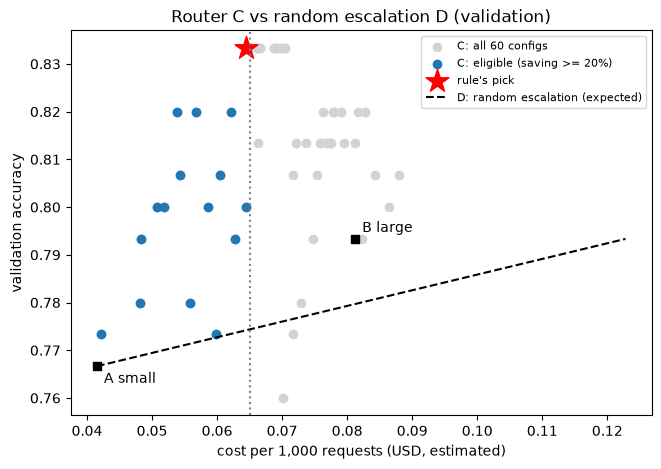

In [13]:
import matplotlib.pyplot as plt

cA   = val.small_cost.mean() * 1000
aA   = val.small_ok.mean()
aB   = val.large_ok.mean()

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(sweep.cost_per_1k, sweep.acc, c="lightgray", label="C: all 60 configs")
el = sweep[sweep.saving >= MIN_SAVING]
ax.scatter(el.cost_per_1k, el.acc, c="tab:blue", label="C: eligible (saving >= 20%)")
ax.scatter(best.cost_per_1k, best.acc, marker="*", s=300, c="red", label="rule's pick")
ax.plot([cA, cA + cost_B], [aA, aB], "k--", label="D: random escalation (expected)")
ax.scatter([cA, cost_B], [aA, aB], c="black", marker="s")
ax.annotate("A small", (cA, aA), textcoords="offset points", xytext=(5, -12))
ax.annotate("B large", (cost_B, aB), textcoords="offset points", xytext=(5, 5))
ax.axvline(cost_B * (1 - MIN_SAVING), color="gray", ls=":")
ax.set_xlabel("cost per 1,000 requests (USD, estimated)")
ax.set_ylabel("validation accuracy")
ax.set_title("Router C vs random escalation D (validation)")
ax.legend(fontsize=8)
plt.show()

## FROZEN CONFIGURATION (chosen on validation only, before any test result for C or D)

Router C: escalate to the large model when the small model's output is invalid
OR the small model's label disagrees with S0's label.
t_v = 0 (verbalized-confidence signal off), t_s = 0 (S0-probability signal off),
use_disagree = True.

Picked by the pre-written rule (highest validation accuracy among configs with
cost saving >= 20% vs B). Validation: accuracy 0.833, escalation 38/150 (25.3%),
saving 20.7%. A tie with t_v=0.5 (identical escalations) went to the simpler config.

D: random escalation at the same count of escalated rows, 2000 draws, seed 0.
Test is computed once with exactly this configuration.

In [14]:
FROZEN = dict(t_v=0, t_s=0, use_disagree=True)

# the frozen config must be the rule's pick, otherwise stop
assert (best.t_v, best.t_s, bool(best.use_disagree)) == \
       (FROZEN["t_v"], FROZEN["t_s"], FROZEN["use_disagree"])

# validation only: on the rows the router keeps vs escalates, who is right?
val["esc"] = route(val, **FROZEN)
print(val.groupby("esc").agg(n=("gold", "size"),
                             small_right=("small_ok", "sum"),
                             large_right=("large_ok", "sum"),
                             s0_right=("s0_ok", "sum")))

         n  small_right  large_right  s0_right
esc                                           
False  112          105           99       105
True    38           10           20        13


## Results

All numbers in this section are computed **once** on the 150 test requests with the frozen configuration, from the cache, with no API calls. The first cell computes the metrics of every system and the headline numbers, the second the bootstrap intervals, the third the headline figure (left: how the configuration was chosen on validation; right: the five test systems with 95% bootstrap intervals on accuracy). The tables and the reading follow the figure.


In [15]:
test = df[df["split"] == "test"].copy()

# ---- C: frozen config, applied once ----
esc_t = route(test, **FROZEN)
k_t   = int(esc_t.sum())
pred, lat, cost = system_C(test, esc_t)
C_t = metrics(test.gold, pred, lat, cost)
C_t["esc_rate"] = esc_t.mean()

# ---- D: random escalation of the same number of rows, full metrics, averaged ----
def run_D_metrics(g, k, n_draws=1000, seed=0):
    rng = np.random.default_rng(seed)
    n = len(g)
    res = []
    for _ in range(n_draws):
        e = np.zeros(n, dtype=bool)
        e[rng.choice(n, size=k, replace=False)] = True
        p, l, c = system_C(g, e)           # same function as C: only WHICH rows differ
        res.append(metrics(g.gold, p, l, c))
    d = pd.DataFrame(res)
    return d.mean(), d.std()

D_t, D_sd = run_D_metrics(test, k_t)
D_t["esc_rate"] = k_t / len(test)

table = pd.DataFrame({
    "S0":       metrics(test.gold, test.s0_pred),
    "A small":  metrics(test.gold, test.small_pred, test.small_latency_s, test.small_cost),
    "B large":  metrics(test.gold, test.large_pred, test.large_latency_s, test.large_cost),
    "C router": C_t,
    "D random": D_t,
}).T
print(table.round(3).to_string(), "\n")

# ---- headline numbers ----
cost_B_t = test.large_cost.mean() * 1000
print(f"escalated: {k_t} of {len(test)}")
print(f"cost saved vs B:          {1 - C_t['cost_per_1k'] / cost_B_t:+.1%}")
print(f"accuracy vs B (C / B):    {C_t['acc'] / table.loc['B large', 'acc']:.1%}")
print(f"C minus D (accuracy):     {C_t['acc'] - D_t['acc']:+.3f}   (D's typical luck-swing, sd: {D_sd['acc']:.3f})")

# sanity: D should sit on the straight line between A and B
a, b = (test.small_pred == test.gold).mean(), (test.large_pred == test.gold).mean()
print(f"straight-line check: expected {a + (k_t/len(test))*(b-a):.3f}, D gave {D_t['acc']:.3f}")

# same split-by-escalation table as on validation
test["esc"] = esc_t
test["small_ok"] = test.small_pred == test.gold
test["large_ok"] = test.large_pred == test.gold
print(test.groupby("esc").agg(n=("gold", "size"), small_right=("small_ok", "sum"), large_right=("large_ok", "sum")))

            acc  cost_per_1k  esc_rate  invalid_rate  lat_median  lat_p95  macro_f1      n
S0        0.800          NaN       NaN         0.000         NaN      NaN     0.791  150.0
A small   0.700        0.042       NaN         0.007       1.432    2.080     0.769  150.0
B large   0.780        0.081       NaN         0.000       1.471    2.308     0.829  150.0
C router  0.773        0.072      0.34         0.000       1.561    3.826     0.815  150.0
D random  0.727        0.070      0.34         0.005       1.610    3.532     0.785  150.0 

escalated: 51 of 150
cost saved vs B:          +11.6%
accuracy vs B (C / B):    99.1%
C minus D (accuracy):     +0.046   (D's typical luck-swing, sd: 0.013)
straight-line check: expected 0.727, D gave 0.727
        n  small_right  large_right
esc                                
False  99           92           93
True   51           13           24


In [16]:
rng = np.random.default_rng(1)
n = len(test)

# per-row facts (True/False or dollars), all from the cache
s_ok = (test.small_pred == test.gold).to_numpy()
l_ok = (test.large_pred == test.gold).to_numpy()
z_ok = (test.s0_pred    == test.gold).to_numpy()
c_ok = np.where(esc_t, l_ok, s_ok)                         # router's correctness per row
c_cost = test.small_cost.to_numpy() + esc_t * test.large_cost.to_numpy()
b_cost = test.large_cost.to_numpy()

B = 5000
idx = rng.integers(0, n, size=(B, n))     # each line = one resample of row positions

def boot(x):                              # the mean of x on each of the 5000 resamples
    return np.asarray(x, dtype=float)[idx].mean(axis=1)

accA, accB, accC, accS = boot(s_ok), boot(l_ok), boot(c_ok), boot(z_ok)
escr   = boot(esc_t)                                   # escalation rate in each resample
accD   = accA + escr * (accB - accA)                   # random escalation's expected accuracy
saving = 1 - boot(c_cost) / boot(b_cost)

# (point estimate on the real test rows, the 5000 resampled values)
Q = {
 "accuracy  A small":          (s_ok.mean(), accA),
 "accuracy  B large":          (l_ok.mean(), accB),
 "accuracy  C router":         (c_ok.mean(), accC),
 "accuracy  S0":               (z_ok.mean(), accS),
 "C minus B  (accuracy)":      (c_ok.mean() - l_ok.mean(), accC - accB),
 "C minus A  (accuracy)":      (c_ok.mean() - s_ok.mean(), accC - accA),
 "C minus S0 (accuracy)":      (c_ok.mean() - z_ok.mean(), accC - accS),
 "C minus D  (accuracy)":      (c_ok.mean() - (s_ok.mean() + esc_t.mean()*(l_ok.mean()-s_ok.mean())), accC - accD),
 "cost saved vs B":            (1 - c_cost.mean() / b_cost.mean(), saving),
 "share of B's accuracy kept": (c_ok.mean() / l_ok.mean(), accC / accB),
}
out = pd.DataFrame(
    [(k, p, *np.percentile(v, [2.5, 97.5])) for k, (p, v) in Q.items()],
    columns=["quantity", "point", "ci_low", "ci_high"]).set_index("quantity")
print(out.round(3).to_string())
print(f"\nshare of resamples where C beats D: {(accC - accD > 0).mean():.1%}")

                            point  ci_low  ci_high
quantity                                          
accuracy  A small           0.700   0.627    0.773
accuracy  B large           0.780   0.713    0.847
accuracy  C router          0.773   0.707    0.840
accuracy  S0                0.800   0.733    0.860
C minus B  (accuracy)      -0.007  -0.033    0.013
C minus A  (accuracy)       0.073   0.020    0.127
C minus S0 (accuracy)      -0.027  -0.087    0.040
C minus D  (accuracy)       0.046   0.011    0.080
cost saved vs B             0.116   0.033    0.202
share of B's accuracy kept  0.991   0.960    1.018

share of resamples where C beats D: 99.6%


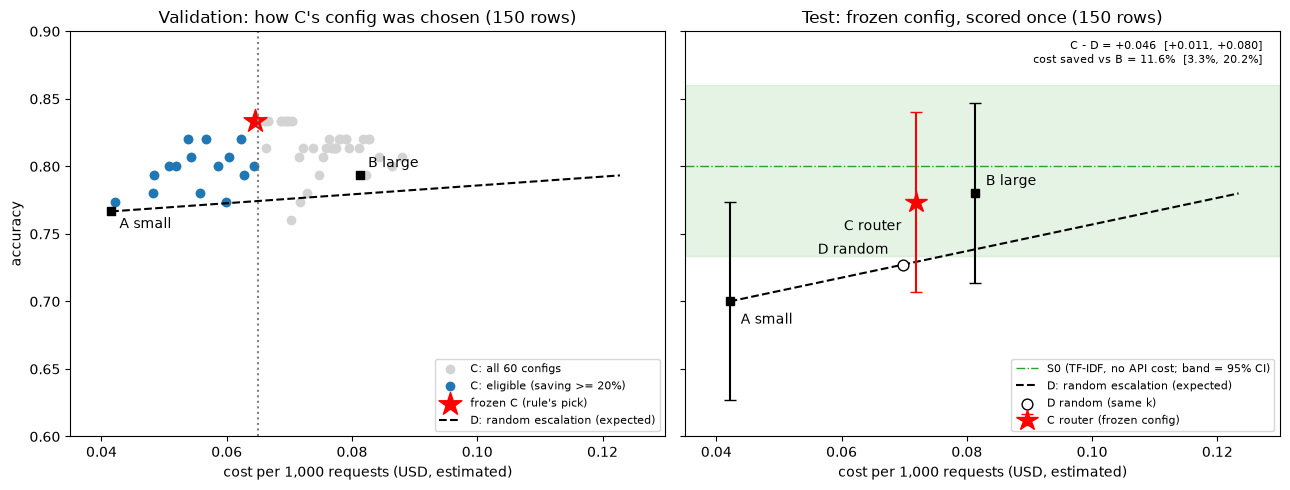

In [17]:
import matplotlib.pyplot as plt

# ---------- 1. pull the numbers (nothing retyped except the checksums) ----------
ci = out.copy()                                          # bootstrap table from cell 15
ci.index = [" ".join(s.split()) for s in ci.index]       # "accuracy  A small" -> "accuracy A small"

# validation side (same quantities as the earlier plot)
cA_v, cB_v = val.small_cost.mean() * 1000, val.large_cost.mean() * 1000
aA_v, aB_v = val.small_ok.mean(), val.large_ok.mean()

# test side
cA_t, cB_t = test.small_cost.mean() * 1000, test.large_cost.mean() * 1000
aA_t, aB_t = ci.loc["accuracy A small", "point"], ci.loc["accuracy B large", "point"]
aC_t, aS_t = ci.loc["accuracy C router", "point"], ci.loc["accuracy S0", "point"]
cC_t, aD_t, cD_t = C_t["cost_per_1k"], D_t["acc"], D_t["cost_per_1k"]

# ---------- 2. checksums against numbers already reported ----------
assert abs(best.acc - 0.8333) < 1e-3 and abs(best.esc_rate - 0.2533) < 1e-3
assert abs(best.saving - 0.2068) < 1e-3 and abs(best.C_minus_D - 0.0599) < 1e-3
assert abs(aC_t - 0.7733) < 1e-3 and abs(aD_t - 0.727) < 1e-3
assert abs(cA_t - 0.042) < 5e-4 and abs(cB_t - 0.081) < 5e-4
assert abs(cC_t - 0.072) < 5e-4 and abs(cD_t - 0.070) < 5e-4
assert abs(ci.loc["accuracy C router", "ci_low"] - 0.707) < 1e-3

# ---------- 3. the figure ----------
fig, (axL, axR) = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

# LEFT: validation sweep
axL.scatter(sweep.cost_per_1k, sweep.acc, c="lightgray", label="C: all 60 configs")
el = sweep[sweep.saving >= MIN_SAVING]
axL.scatter(el.cost_per_1k, el.acc, c="tab:blue", label="C: eligible (saving >= 20%)")
axL.scatter(best.cost_per_1k, best.acc, marker="*", s=300, c="red", label="frozen C (rule's pick)")
axL.plot([cA_v, cA_v + cB_v], [aA_v, aB_v], "k--", label="D: random escalation (expected)")
axL.scatter([cA_v, cB_v], [aA_v, aB_v], c="black", marker="s")
axL.annotate("A small", (cA_v, aA_v), textcoords="offset points", xytext=(6, -12))
axL.annotate("B large", (cB_v, aB_v), textcoords="offset points", xytext=(6, 6))
axL.axvline(cB_v * (1 - MIN_SAVING), color="gray", ls=":")
axL.set_title("Validation: how C's config was chosen (150 rows)")
axL.set_xlabel("cost per 1,000 requests (USD, estimated)")
axL.set_ylabel("accuracy")
axL.legend(fontsize=8, loc="lower right")

# RIGHT: test, scored once, 95% bootstrap CI bars
axR.axhspan(ci.loc["accuracy S0", "ci_low"], ci.loc["accuracy S0", "ci_high"],
            color="tab:green", alpha=0.12)
axR.axhline(aS_t, color="tab:green", ls="-.", lw=1, label="S0 (TF-IDF, no API cost; band = 95% CI)")
axR.plot([cA_t, cA_t + cB_t], [aA_t, aB_t], "k--", label="D: random escalation (expected)")

def bar(x, key):                                         # asymmetric error bar from the bootstrap table
    p, lo, hi = ci.loc[key, ["point", "ci_low", "ci_high"]]
    return [[p - lo], [hi - p]]

axR.errorbar(cA_t, aA_t, yerr=bar(cA_t, "accuracy A small"), fmt="s", c="black", capsize=4)
axR.errorbar(cB_t, aB_t, yerr=bar(cB_t, "accuracy B large"), fmt="s", c="black", capsize=4)
axR.errorbar(cC_t, aC_t, yerr=bar(cC_t, "accuracy C router"), fmt="*", c="red", ms=16, capsize=4,
             label="C router (frozen config)")
axR.scatter(cD_t, aD_t, facecolors="white", edgecolors="black", s=60, zorder=3, label="D random (same k)")

#axR.annotate("A small",  (cA_t, aA_t), textcoords="offset points", xytext=(8, -3))
axR.annotate("B large",  (cB_t, aB_t), textcoords="offset points", xytext=(8, 6))
axR.annotate("C router", (cC_t, aC_t), textcoords="offset points", xytext=(-10, -20), ha="right")
#axR.annotate("D random", (cD_t, aD_t), textcoords="offset points", xytext=(-10, -3), ha="right")
axR.annotate("A small",  (cA_t, aA_t), textcoords="offset points", xytext=(8, -16))
axR.annotate("D random", (cD_t, aD_t), textcoords="offset points", xytext=(-10, 8), ha="right")

d, s = ci.loc["C minus D (accuracy)"], ci.loc["cost saved vs B"]
axR.text(0.97, 0.98,
         f"C - D = {d.point:+.3f}  [{d.ci_low:+.3f}, {d.ci_high:+.3f}]\n"
         f"cost saved vs B = {s.point:.1%}  [{s.ci_low:.1%}, {s.ci_high:.1%}]",
         transform=axR.transAxes, ha="right", va="top", fontsize=8)
axR.set_title("Test: frozen config, scored once (150 rows)")
axR.set_xlabel("cost per 1,000 requests (USD, estimated)")
axR.legend(fontsize=8, loc="lower right")

axL.set_xlim(0.035, 0.13)
axL.set_ylim(0.60, 0.90)
plt.tight_layout()
plt.show()

## Results (test split, 150 requests, frozen configuration scored once)

![headline figure above]

| System | Accuracy | Macro-F1 | Cost per 1,000 (USD) | Escalated | Latency median / p95 (s) |
|---|---|---|---|---|---|
| S0 (TF-IDF + logistic regression) | 0.800 | 0.791 | n/a | n/a | n/a |
| A: small model only | 0.700 | 0.769 | 0.042 | n/a | 1.43 / 2.08 |
| B: large model only | 0.780 | 0.829 | 0.081 | n/a | 1.47 / 2.31 |
| **C: router** | 0.773 | 0.815 | 0.072 | 34% (51 of 150) | 1.56 / 3.83 |
| D: random escalation, same count | 0.727 | 0.785 | 0.070 | 34% | 1.61 / 3.53 |

Cost is estimated from published per-token prices (free tier used). Router latency is the sum of two separately measured calls, not a stopwatch on a running pipeline. Macro-F1 is computed over the classes present in the sample.

**Uncertainty.** With 150 rows, differences must be read with intervals. Paired bootstrap, 5,000 resamples, routing decisions held fixed:

| Quantity | Estimate | 95% interval | Reading |
|---|---|---|---|
| C minus D (accuracy) | +0.046 | [+0.011, +0.080] | solid (C beats D in 99.6% of resamples) |
| C minus A | +0.073 | [+0.020, +0.127] | solid |
| C minus B | -0.007 | [-0.033, +0.013] | tie |
| C minus S0 | -0.027 | [-0.087, +0.040] | tie |
| Cost saved vs B | 11.6% | [3.3%, 20.2%] | modest, wide |
| Share of B's accuracy kept | 99.1% | [96.0%, 101.8%] | consistent with all of it |

I give no intervals for macro-F1 or latency (too noisy at n = 150), so those columns are descriptive only. "Tie" means the data cannot distinguish the two systems, not that they are equal.

**From validation to test.** On validation, C had 0.833 accuracy against B's 0.793 and saved 20.7% of B's cost. On test, the advantage over B disappeared (a tie) and the saving was 11.6%. The 20% saving floor was used only to filter validation configurations, so the test saving is reported as it came out.



### Error analysis: the code behind the section that follows

Test errors can now be read, because the thresholds are frozen and the test is spent; **nothing found here changes the frozen configuration.** Each cell derives True/False columns and checks them with `assert` against numbers computed earlier (51 escalated rows, the 28 / 13 / 10 split, 45 small-model errors, 116 correct answers for C, a ledger that sums to 150), so the analysis stays tied to the headline results. The summary of what these cells show comes right after them.


In [18]:
e = test[test.esc].copy()
e["s0_ok"] = e.s0_pred == e.gold
e["who"] = np.select(
    [e.small_ok & ~e.s0_ok, ~e.small_ok & e.s0_ok, ~e.small_ok & ~e.s0_ok],
    ["small only right", "S0 only right", "neither right"], default="both right")
print(e.groupby("who").agg(n=("gold", "size"), large_right=("large_ok", "sum")))

                   n  large_right
who                              
S0 only right     28           14
neither right     10            0
small only right  13           10


In [19]:
print(test.shape)
print(test.dtypes)
print(type(esc_t), len(esc_t))
print(esc_t[:5])
test.head(2).T

(150, 30)
split                          str
id                           int64
small_pred                     str
small_confidence           float64
small_json_ok                 bool
small_label_ok                bool
small_finish_reason            str
small_latency_s            float64
small_prompt_tokens          int64
small_completion_tokens      int64
small_reasoning_tokens       int64
small_text                     str
large_pred                     str
large_confidence           float64
large_json_ok                 bool
large_label_ok                bool
large_finish_reason            str
large_latency_s            float64
large_prompt_tokens          int64
large_completion_tokens      int64
large_reasoning_tokens       int64
large_text                     str
gold                           str
s0_pred                        str
s0_conf                    float64
small_cost                 float64
large_cost                 float64
esc                           bool
small_ok  

,150,151
split,test,test
id,13983,16652
small_pred,general_quirky,email_query
small_confidence,0.6,0.92
small_json_ok,True,True
small_label_ok,True,True
small_finish_reason,stop,stop
small_latency_s,1.511907,1.287779
small_prompt_tokens,358,362
small_completion_tokens,121,41


In [20]:
import numpy as np

# 1. the missing column
test["s0_ok"] = test["s0_pred"] == test["gold"]

# 2. tripwires: do the existing columns mean what we think?
assert (test["small_ok"] == (test["small_pred"] == test["gold"])).all()
assert (test["large_ok"] == (test["large_pred"] == test["gold"])).all()
assert (test["esc"].to_numpy() == esc_t).all()
assert test["esc"].sum() == 51

# 3. kept vs escalated
kept = test[~test["esc"]]
escd = test[test["esc"]].copy()

print("kept      ", len(kept), "| small right", kept["small_ok"].sum(),
      "| large right", kept["large_ok"].sum())
print("escalated ", len(escd), "| small right", escd["small_ok"].sum(),
      "| large right", escd["large_ok"].sum())

# 4. who is right on the escalated rows
escd["group"] = np.select(
    [escd["s0_ok"] & ~escd["small_ok"],
     escd["small_ok"] & ~escd["s0_ok"],
     escd["small_ok"] & escd["s0_ok"]],
    ["S0 only right", "small only right", "both right"],
    default="neither right",
)
who_table = escd.groupby("group").agg(rows=("group", "size"),
                                      large_right=("large_ok", "sum"))
print(who_table)

# 5. checksum against the numbers already reported
assert who_table.loc["S0 only right"].tolist() == [28, 14]
assert who_table.loc["small only right"].tolist() == [13, 10]
assert who_table.loc["neither right"].tolist() == [10, 0]
assert "both right" not in who_table.index

kept       99 | small right 92 | large right 93
escalated  51 | small right 13 | large right 24
                  rows  large_right
group                              
S0 only right       28           14
neither right       10            0
small only right    13           10


In [21]:
# 1. scenario = the part of the intent name before the first underscore
test["gold_scn"]  = test["gold"].str.split("_").str[0]
test["small_scn"] = test["small_pred"].str.split("_").str[0]

# 2. "wrong" columns (the opposite of *_ok)
for m in ["s0", "small", "large"]:
    test[m + "_err"] = ~test[m + "_ok"]

errs = test[test["small_err"]]
assert len(errs) == 45
print("small errors: escalated", errs["esc"].sum(), "| kept", (~errs["esc"]).sum())

# 3. errors by scenario, for all three systems
by_scn = (test.groupby("gold_scn")
              .agg(rows=("gold", "size"),
                   small_wrong=("small_err", "sum"),
                   s0_wrong=("s0_err", "sum"),
                   large_wrong=("large_err", "sum"))
              .sort_values("small_wrong", ascending=False))
assert by_scn["small_wrong"].sum() == 45
print(by_scn)

# 4. inside the right scenario or not
same = errs["gold_scn"] == errs["small_scn"]
print("small errors inside the right scenario:", same.sum(), "of", len(errs))

# 5. the 45 errors, readable
cols = ["gold", "small_pred", "s0_pred", "large_pred", "esc"]
print(errs.sort_values("gold")[cols].to_string(index=False))

small errors: escalated 38 | kept 7
                rows  small_wrong  s0_wrong  large_wrong
gold_scn                                                
general           15            9         6            8
calendar          23            9         5            7
play              28            9         5            7
qa                12            5         2            3
email             12            3         2            1
recommendation     7            2         1            0
social             6            2         2            2
takeaway           4            2         1            2
cooking            2            1         0            0
news               3            1         1            1
transport          4            1         1            0
music              4            1         1            1
audio              1            0         0            0
alarm              6            0         1            0
lists              4            0         0         

In [22]:
# 0. recheck the two hand counts from A2
print("errors touching 'general':",
      (test["small_err"] & ((test["gold_scn"] == "general") | (test["small_scn"] == "general"))).sum())
print("small errors predicting play_music:", (errs["small_pred"] == "play_music").sum())

# 1. what C finally answers, and whether it is right
test["c_ok"] = np.where(test["esc"], test["large_ok"], test["small_ok"])
assert test["c_ok"].sum() == 116
assert round(test["c_ok"].mean(), 3) == 0.773

# 2. the 8-bucket ledger
e, s, l, z = test["esc"], test["small_ok"], test["large_ok"], test["s0_ok"]
test["outcome"] = np.select(
    [~e & s,
     ~e & ~s & l,
     ~e & ~s & ~l,
     e & s & l,
     e & s & ~l,
     e & ~s & l,
     e & ~s & ~l & z],
    ["1 kept, right",
     "2 kept, wrong (large would fix)",
     "3 kept, wrong (large no help)",
     "4 escalated, wasted",
     "5 escalated, BROKE a right answer",
     "6 escalated, FIXED a wrong answer",
     "7 escalated, still wrong (S0 had it)"],
    default="8 escalated, still wrong (nobody)",
)
ledger = test["outcome"].value_counts().sort_index()
print(ledger)
assert ledger.sum() == 150
assert ledger.tolist() == [92, 2, 5, 10, 3, 14, 14, 10]

# 3. the rows behind the interesting buckets
cols = ["gold", "small_pred", "s0_pred", "large_pred"]
for name in ["5 escalated, BROKE a right answer",
             "8 escalated, still wrong (nobody)",
             "2 kept, wrong (large would fix)"]:
    print("\n", name)
    print(test[test["outcome"] == name][cols].to_string(index=False))

errors touching 'general': 22
small errors predicting play_music: 7
outcome
1 kept, right                           92
2 kept, wrong (large would fix)          2
3 kept, wrong (large no help)            5
4 escalated, wasted                     10
5 escalated, BROKE a right answer        3
6 escalated, FIXED a wrong answer       14
7 escalated, still wrong (S0 had it)    14
8 escalated, still wrong (nobody)       10
Name: count, dtype: int64

 5 escalated, BROKE a right answer
           gold      small_pred         s0_pred      large_pred
 general_quirky  general_quirky   qa_definition   qa_definition
 general_quirky  general_quirky    social_query      qa_factoid
iot_hue_lighton iot_hue_lighton iot_hue_lightup iot_hue_lightup

 8 escalated, still wrong (nobody)
          gold            small_pred               s0_pred       large_pred
calendar_query recommendation_events        datetime_query   datetime_query
    play_music        datetime_query        general_quirky datetime_conver

In [23]:
import json
from data import load_massive

dfs, _ = load_massive()                      # cached by HF after Day 1
raw = dfs["test"].copy()
raw["id"] = raw["id"].astype(int)            

utt_map   = dict(zip(raw["id"], raw["utt"]))
label_map = dict(zip(raw["id"], raw["label"]))

# 1. join by lookup
test["utt"] = test["id"].map(utt_map)

# 2. tripwires
assert test["utt"].notna().all()
assert (test["id"].map(label_map) == test["gold"]).all()
frozen_ids = {int(i) for i in json.load(open("samples.json"))["test"]}
assert set(test["id"]) == frozen_ids

# 3. read the hard rows
cols = ["utt", "gold", "small_pred", "s0_pred", "large_pred"]
for name in ["5 escalated, BROKE a right answer",
             "8 escalated, still wrong (nobody)",
             "2 kept, wrong (large would fix)"]:
    print("\n", name)
    print(test[test["outcome"] == name][cols].to_string(index=False, max_colwidth=70))


 5 escalated, BROKE a right answer
                                 utt            gold      small_pred         s0_pred      large_pred
describe the new football game rules  general_quirky  general_quirky   qa_definition   qa_definition
       tell me what i wore yesterday  general_quirky  general_quirky    social_query      qa_factoid
  light up the lights in the kitchen iot_hue_lighton iot_hue_lighton iot_hue_lightup iot_hue_lightup

 8 escalated, still wrong (nobody)
                                            utt           gold            small_pred               s0_pred       large_pred
     what time will the soccer match be tonight calendar_query recommendation_events        datetime_query   datetime_query
                                    seven years     play_music        datetime_query        general_quirky datetime_convert
                                          topic    email_query         general_greet            news_query   general_quirky
   google what are the basic

In [24]:
VERDICT = {
    # bucket 5: escalation broke a right answer
    "describe the new football game rules":               "defensible alternative",
    "tell me what i wore yesterday":                      "model mistake",
    "light up the lights in the kitchen":                 "defensible alternative",
    # bucket 8: escalated, nobody right
    "what time will the soccer match be tonight":         "defensible alternative",
    "seven years":                                        "not recoverable",
    "topic":                                              "not recoverable",
    "google what are the basic things humans need":       "defensible alternative",
    "playback tom clancy splinter cell":                  "defensible alternative",
    "who takes less of duration of time for delivery":    "model mistake",
    "is there any special in politic":                    "model mistake",
    "wedding wishes":                                     "not recoverable",
    "is today saint patricks day":                        "model mistake",
    "tell me if global warming is true":                  "defensible alternative",
    # bucket 2: kept, large would have fixed
    "find a train ticket to philadelphia":                "model mistake",
    "show me reviews of my nearest location food court":  "model mistake",
}
assert len(VERDICT) == 15

test["verdict"] = test["utt"].map(VERDICT)
hard = test[test["verdict"].notna()]
assert len(hard) == 15
assert hard["verdict"].value_counts().to_dict() == {"defensible alternative": 6, "not recoverable": 3, "model mistake": 6}
print(hard.groupby(["outcome", "verdict"]).size())

outcome                            verdict               
2 kept, wrong (large would fix)    model mistake             2
5 escalated, BROKE a right answer  defensible alternative    2
                                   model mistake             1
8 escalated, still wrong (nobody)  defensible alternative    4
                                   model mistake             3
                                   not recoverable           3
dtype: int64


In [25]:
import pandas as pd

assert len(df) == 300

# 1. how did the 300 calls end, per model?
rows = []
for m in ["small", "large"]:
    rows.append({
        "model": m,
        "json_failed":       int((~df[m + "_json_ok"]).sum()),
        "label_outside_60":  int((df[m + "_json_ok"] & ~df[m + "_label_ok"]).sum()),
        "finish_not_stop":   int((df[m + "_finish_reason"] != "stop").sum()),
        "median_compl_tok":  int(df[m + "_completion_tokens"].median()),
        "max_compl_tok":     int(df[m + "_completion_tokens"].max()),
    })
summary = pd.DataFrame(rows).set_index("model")
print(summary)
assert int(df["small_json_ok"].sum() + df["large_json_ok"].sum()) == 598

# 2. the failed or cut-off calls, row by row
for m in ["small", "large"]:
    bad = df[(~df[m + "_json_ok"]) | (df[m + "_finish_reason"] != "stop")]
    print("\n", m, "-", len(bad), "row(s)")
    print(bad[["split", "id", m + "_pred", m + "_finish_reason",
               m + "_completion_tokens", m + "_reasoning_tokens",
               m + "_text"]].to_string(index=False))

# 3. what the router did with the failed test row(s)
t_bad = test[~test["small_json_ok"]]
print("\ntest rows where small failed:", len(t_bad))
print(t_bad[["utt", "gold", "small_pred", "s0_pred", "large_pred",
             "esc", "outcome"]].to_string(index=False, max_colwidth=60))

       json_failed  label_outside_60  finish_not_stop  median_compl_tok  \
model                                                                     
small            2                 0                2                36   
large            0                 0                0                39   

       max_compl_tok  
model                 
small            400  
large            113  

 small - 2 row(s)
     split    id small_pred small_finish_reason  small_completion_tokens  small_reasoning_tokens small_text
validation 16709    INVALID              length                      400                     398           
      test 14348    INVALID              length                      400                     396           

 large - 0 row(s)
Empty DataFrame
Columns: [split, id, large_pred, large_finish_reason, large_completion_tokens, large_reasoning_tokens, large_text]
Index: []

test rows where small failed: 1
                                         utt           gold small_pred 

## Error analysis (test split, 150 rows)

**How to read this section.** The test split was scored once, with the frozen router (the commit "Freeze router config" precedes the commit with test results). Here I read the test errors only to understand them. Nothing below changes the frozen configuration. Every number comes from a cell above with an `assert` that checks it against the headline results.

**Summary in plain words.** The small model gets 105 of 150 test rows right. The router sends 51 rows to the large model and catches 38 of the small model's 45 errors, but only 14 of those 38 end up fixed. In most of the others the large model gives the same wrong answer as the small one, or the gold label itself is arguable. The router cannot see the 7 errors where the small model and the TF-IDF baseline (S0) agree on the same wrong label.

### 1. Where the small model fails (45 wrong of 150)

Intent names look like `scenario_intent` (for example `email_query`), so I group by the part before the first underscore (18 scenarios appear in the sample).

- **Three scenarios hold most errors.** `general` (9 of 15 rows wrong), `calendar` (9 of 23) and `play` (9 of 28) hold 27 of the small model's 45 errors (60%) but only 66 of the 150 rows (44%). The same three scenarios hold 16 of S0's 30 errors and 22 of the large model's 33. So they are hard for every system, which points at the data and labels more than at the small model alone. With 3 to 28 rows per scenario, this is a description, not a ranking of scenarios.
- **Most errors leave the right scenario.** Only 17 of 45 stay inside the correct scenario (for example `email_query` vs `email_querycontact`). The other 28 land in an unrelated scenario. Neighbouring-label confusion is real but explains a minority of errors. (I predicted the opposite before computing this, and was wrong.)
- **`general_*` acts as a hub.** 22 of the 45 errors involve a `general_*` label, either as the gold label or as the small model's prediction.
- **`play_music` absorbs its neighbours.** The small model predicts `play_music` on 7 errors (4 gold `play_audiobook`, 3 gold `play_radio`).

### 2. What the router did, row by row

Every test row falls in exactly one bucket (the counts add to 150, and the correct answers 92 + 10 + 14 = 116 reproduce C's accuracy of 0.773).

| Bucket | Rows | Meaning |
|---|---|---|
| 1 kept, right | 92 | small model right, not escalated |
| 2 kept, wrong, large would fix | 2 | missed by the router, escalation would have helped |
| 3 kept, wrong, large no help | 5 | missed, but large would also be wrong |
| 4 escalated, wasted | 10 | small was already right, large also right |
| 5 escalated, broke a right answer | 3 | small right, large wrong |
| 6 escalated, fixed a wrong answer | 14 | small wrong, large right |
| 7 escalated, still wrong (S0 had it) | 14 | small and large wrong, S0 right |
| 8 escalated, still wrong (nobody) | 10 | small, large and S0 all wrong |

- **Kept rows:** 99 (92 right, 7 wrong). **Escalated rows:** 51. C is wrong on 34 rows (7 kept + 27 escalated).
- **The router flags well.** It escalates 38 of the 45 small-model errors (13 false alarms, where small was right).
- **Escalation pays off in a minority of cases.** Of 51 escalations, 14 improved the answer (27%), 3 made it worse, and 34 changed nothing. The net gain is 14 - 3 = +11 correct answers, which is exactly C's lead over small-only (116 vs 105).
- **Large fixed rows only when S0 was also right.** All 14 fixes are rows where S0 was also right, and the large model was right on 0 of the 10 rows where both small and S0 were wrong. With only 10 such rows, I read this as "0 of 10", not "never". It is the motivation for a cascade that asks S0 first (future work, not tested here).
- **The 7 kept errors are invisible to this router by construction.** Small and S0 agree on a wrong label. The large model gave the same wrong label on 4 of them, a different wrong label on 1, and the right label on 2 (the two bucket-2 rows).

### 3. Reading the 15 hardest rows

I attached the actual utterances to buckets 2, 5 and 8 (15 rows) and judged each one by reading it. Verdicts: **model mistake** (the gold label looks right), **defensible alternative** (a reasonable annotator could have chosen the label the models chose), **not recoverable** (the text does not contain enough to find the gold label).

| Bucket | Model mistake | Defensible alternative | Not recoverable |
|---|---|---|---|
| 2 (kept, large would fix; 2 rows) | 2 | 0 | 0 |
| 5 (escalation broke a right answer; 3 rows) | 1 | 2 | 0 |
| 8 (nobody right; 10 rows) | 3 | 4 | 3 |
| **Total (15 rows)** | **6** | **6** | **3** |

Examples: "light up the lights in the kitchen" has gold `iot_hue_lighton`, but the models chose `iot_hue_lightup`, a near word-for-word match with the request. "seven years", "topic" and "wedding wishes" carry almost no signal.

**What this does and does not show.** These 15 rows were selected because they are the hardest buckets, not drawn at random, and one reading is a judgment call, not a measurement. The defensible claim is: 
*of the 15 hardest test rows, 9 had a defensible alternative label or no recoverable signal in my final reading but the count depends on the reader.*


### 4. Invalid outputs, truncation and hallucination

In this task the model must pick one label from a closed list of 60, so "hallucination" has a precise meaning: output that parses but names an intent outside the 60.

- **Invented labels: 0 of 598 parsed outputs** (600 calls, both models, validation and test).
- **No answer at all: 2 calls, both from the small model** (one validation row, one test row). Both stopped with `finish_reason = length` at the 400-token cap, with 398 and 396 of those 400 tokens spent on hidden reasoning, so the JSON answer was never written. The large model had 0 failures (maximum 113 completion tokens).
- **Cause vs. explanation.** The reasoning overrun is measured. Why the small model overthinks those two requests is a hypothesis (the test one, "google what are the basic things humans need", is a vague request). 
- **The router handled the test failure as designed.** The invalid output was escalated (cost: one large call). The large model still answered `qa_factoid` against gold `general_quirky`, which I judge defensible.
- **The real failure modes are wrong-but-valid labels,** mistakes shared by several systems, and overconfident stated confidence (see the calibration section: on validation, 22 of the large model's 31 errors carried a stated confidence of 0.92 or higher).

### 5. Cost side note

Per token the large model costs exactly twice the small one (input 0.15 vs 0.075, output 0.60 vs 0.30 dollars per million). The observed cost ratio on test is about 1.94x, slightly below 2. Median completion length is similar (36 tokens for small, 39 for large, over 300 rows). So the cost gap comes mostly from the provider's price list, not from one model being more verbose, and it would change if prices change. 

### 6. What I did not verify

- Whether escalated rows cost slightly more per request because reasoning models think longer on hard inputs.
- Whether the large model's better macro-F1 than S0 on test comes from rare classes.
- Whether the small model's two truncated requests are ambiguous .
- Signal ablation (which parts of the router rule matter) was not done.

### 7. How this section was built

Each analysis step added derived True/False columns (`s0_ok`, `small_ok`, `large_ok`, `c_ok`) and then checked them with `assert` statements against numbers computed earlier (51 escalated, 28/13/10 split, 45 small errors, 116 correct, ledger sums to 150). The utterance join was checked by confirming that the dataset's label matches the stored gold label on all 150 rows and that the 150 ids equal `samples.json`. 

## Interpretation

**1. Routing kept almost all of the large model's accuracy at a smaller cost, but the saving is modest.** C reached 99% of B's accuracy at 88% of its cost, and it is clearly better than the small model alone. It is also about 1.7 times as expensive as the small model alone (0.072 vs 0.042) for +7.3 accuracy points. The saving over B is small because the router always pays for the small model and then pays for the large model on 34% of requests; the large model costs about twice the small one per token (the price list), so there is little room.

**2. The router's choices carry real information.** At the same number of escalated rows, random escalation (D) is clearly worse. The signal that does the work is disagreement with S0. On validation, the small model was right 94% of the time when it agreed with S0 (112 rows) and 26% of the time when it disagreed (38 rows). The models' own stated confidence was a weaker signal: it is "steppy" (131 of 150 validation answers at 0.92 or above) and overconfident (in the top bin, stated 0.99 and 0.97 against 90% actual accuracy for small and large).

**3. Escalation pays off in a minority of cases.** Of 51 escalations on test, 14 fixed a wrong answer (27%), 3 broke a right one, and 34 changed nothing. Net gain: +11 correct answers. On the 10 rows where both the small model and S0 were wrong, the large model was right 0 times;by my final reading of the utterances, 7 of those 10 have a defensible alternative label or no recoverable signal (the other 3 are model mistakes), so "0 of 10" is only partly evidence about the large model.
**4. The router does not beat the cheapest non-LLM baseline.** S0 scores 0.800 against C's 0.773 (tie within noise). The honest framing is cold start: the LLMs need no labelled examples, while S0 needs 11,514, and C needs S0 to route, so it inherits that requirement. A cascade that asks S0 first is the obvious next experiment, motivated by the 14 escalated rows where S0 alone was right and C paid for two models. It is future work and is not tested here.

**5. The validation advantage over B did not carry over.** Best-of-60 configurations on 150 rows invites a winner's curse (hypothesis). On the rows the router kept, the small model beat the large one on validation (105 vs 99 right) but tied on test (92 vs 93). The idea that S0 acts as a second opinion that fixes the large model's convention errors is therefore not supported.

**6. Latency.** The router's median (1.56 s) is close to B's, but its 95th percentile (3.83 s) is much worse than B's (2.31 s), because escalated requests wait for two calls in sequence. Hosted-API latency includes network and queueing, so these numbers do not show that model size causes latency.

**7. Hallucinations and errors.** Across 598 parsed outputs, none named an intent outside the 60. Two small-model calls produced no answer (they ran out of the 400-token budget while "thinking"). The real failures are valid-but-wrong labels, often the same wrong label from both models (16 of 23 both-wrong validation rows), and overconfident stated confidence.

## Limits and perspectives

### Limits

**Statistical**
- Only 150 test requests: the intervals are wide, and "tie" means "cannot distinguish", not "equal". The 95% interval for the cost saving versus B (3.3% to 20.2%) is wide as well.
- The router was chosen as the best of 60 configurations on 150 validation requests, which invites a winner's curse (hypothesis). Its validation advantage over B did not carry over to test.
- The 15 hardest rows were read by one reader and were selected as the hardest, not drawn at random. They illustrate; they do not estimate a label-noise rate.

**Design and scope**
- One dataset, one task (closed-set intent classification, English), one model family (gpt-oss, reasoning effort low). MASSIVE is derived from SLURP, not from production logs.
- The two models differ about 5-6 times in total parameters but much less in active parameters per token (5.1B versus 3.6B, per the model card). This may explain why their latencies are similar .
- S0 is trained on 11,514 labelled requests while the LLMs are zero-shot, so S0 versus LLM is not like for like; and C needs S0, so it inherits S0's need for labels.
- With `t_v = t_s = 0`, the only active signals are an invalid output (1 row on validation) and disagreement with S0 (38 rows), so the frozen router is in practice "escalate on disagreement". No signal ablation was done.
- The router only chooses between two cached predictions; it cannot re-prompt or combine them.
- The prompt gives label names only. Label conventions overlap (`email_query` versus `email_querycontact`, `iot_hue_lighton` versus `iot_hue_lightup`), and a prompt with descriptions or examples might change both models' errors; this was not tested.

**Measurement**
- Cost is **estimated** from published prices (free plan used); the savings depend on the 2x price ratio and would change with prices.
- Latency comes from a hosted API and includes network and queueing, so it does not show that size causes latency. The router's latency is a sum of two separately measured calls, not a measured pipeline.
- Stated confidence is generated text, "steppy" and overconfident; it is not a probability.
- Two small-model calls hit the 400-token cap while still reasoning and returned nothing (a cap artifact). A larger cap might have avoided them, but the parameters were locked.
- Hypotheses that I did not verify are listed at the end of the error-analysis section.

### Perspectives (planned, with the rules fixed in advance)

1. **Test extension.** Score 300 additional test requests not in `samples.json`, keeping the frozen configuration unchanged.
2. **Prompt experiment:** label names only versus names with short descriptions.
4. **Further ideas:** a learned router (for example logistic regression on the signals, with cross-validation), retrieved few-shot examples, slot filling, Arabic, a mid-size model, out-of-scope requests, and a small demo application.


## Conclusion

**Answer to the question.** On this task and sample, a simple router (escalate when the small model's output is invalid or disagrees with a TF-IDF classifier) kept about 99% of the large model's accuracy (95% interval 96% to 102%) at about 88% of its estimated cost. Scored once on 150 held-out requests, it reached 0.773 accuracy against 0.780 for the large model alone and 0.700 for the small model alone; escalating 34% of requests (51 of 150).

**What the controls say.**
- The routing is informative: it beats random escalation with the same number of escalations by 4.6 points (interval +1.1 to +8.0) and beats the small model alone by 7.3 points (+2.0 to +12.7).
- It cannot be distinguished from the large model alone (-0.7 points, interval -3.3 to +1.3) nor from the TF-IDF baseline (-2.7, interval -8.7 to +4.0).
- The saving over the large model is modest (11.6%, interval 3.3% to 20.2%), below the 20% floor used to filter configurations on validation. The router always pays for the small model, and the price ratio is only 2x. Its 95th-percentile latency is clearly worse (3.83 s versus 2.31 s) because escalated requests wait for two calls.

**Where it helps and where it does not.**
- Of the 51 escalations on test, 14 fixed a wrong answer, 3 broke a right one and 34 changed nothing. The 7 errors where the small model and S0 agree on the same wrong label are invisible to this router.
- On the 10 escalated rows where small and S0 were both wrong, the large model was right 0 times, by my  reading 7 of those 10 have a defensible alternative label or no recoverable signal.
- No answer named an intent outside the 60 (0 of 598 parsed outputs). The real failures are valid-but-wrong labels, mistakes shared between models, and overconfident stated confidence.

**Honest bottom line.** With these models and prices, the router is a modest saving at near-equal accuracy, and it does not beat a TF-IDF classifier that has 11.5k labels. Its value is conditional: when no labelled data exists (cold start) and every call is billed. The first thing I would test next is the S0-first cascade, which targets exactly the rows where this router pays twice for an answer S0 already had.

**What I learned.** A control such as random escalation at equal cost is what turns "the router seems good" into a claim; a validation win must be checked on a frozen test; and many of the hardest errors are partly a labelling question (9 of the 15 hardest test rows, by my reading), which no router can fix.


## Use of generative-AI tools (disclosure)

I used an AI assistant (Claude, by Anthropic, in a chat interface) throughout this project.



## References

- Bastianelli, E., Vanzo, A., Swietojanski, P., and Rieser, V. (2020). SLURP: A Spoken Language Understanding Resource Package. *Proceedings of EMNLP 2020*. https://aclanthology.org/2020.emnlp-main.588
- Chen, L., Zaharia, M., and Zou, J. (2024). FrugalGPT: How to Use Large Language Models While Reducing Cost and Improving Performance. *Transactions on Machine Learning Research*. arXiv:2305.05176.
- Ding, D., Mallick, A., Wang, C., Sim, R., Mukherjee, S., Rühle, V., Lakshmanan, L. V. S., and Awadallah, A. H. (2024). Hybrid LLM: Cost-Efficient and Quality-Aware Query Routing. *ICLR 2024*. arXiv:2404.14618.
- Efron, B., and Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman and Hall.
- FitzGerald, J., Hench, C., Peris, C., Mackie, S., Rottmann, K., Sanchez, A., Nash, A., Urbach, L., Kakarala, V., Singh, R., Ranganath, S., Crist, L., Britan, M., Leeuwis, W., Tur, G., and Natarajan, P. (2023). MASSIVE: A 1M-Example Multilingual Natural Language Understanding Dataset with 51 Typologically-Diverse Languages. *Proceedings of ACL 2023*, pp. 4277-4302. https://aclanthology.org/2023.acl-long.235
- Guo, C., Pleiss, G., Sun, Y., and Weinberger, K. Q. (2017). On Calibration of Modern Neural Networks. *Proceedings of ICML 2017*, PMLR 70:1321-1330. https://proceedings.mlr.press/v70/guo17a.html
- Ong, I., Almahairi, A., Wu, V., Chiang, W.-L., Wu, T., Gonzalez, J. E., Kadous, M. W., and Stoica, I. (2025). RouteLLM: Learning to Route LLMs with Preference Data. *ICLR 2025*. arXiv:2406.18665.
- OpenAI (2025). gpt-oss-120b and gpt-oss-20b Model Card. arXiv:2508.10925.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12:2825-2830.
- Tian, K., Mitchell, E., Zhou, A., Sharma, A., Rafailov, R., Yao, H., Finn, C., and Manning, C. D. (2023). Just Ask for Calibration: Strategies for Eliciting Calibrated Confidence Scores from Language Models Fine-Tuned with Human Feedback. *Proceedings of EMNLP 2023*, pp. 5433-5442. https://aclanthology.org/2023.emnlp-main.330
- Xiong, M., Hu, Z., Lu, X., Li, Y., Fu, J., He, J., and Hooi, B. (2024). Can LLMs Express Their Uncertainty? An Empirical Evaluation of Confidence Elicitation in LLMs. *ICLR 2024*. arXiv:2306.13063.

**Dataset link:** https://huggingface.co/datasets/AmazonScience/massive (English-US portion). **Models:** `openai/gpt-oss-20b` and `openai/gpt-oss-120b`, via the Groq API.
